DATASET SETUPS

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, roc_curve, ConfusionMatrixDisplay
)

# Fix random seed for reproducibility
SEED = 42
np.random.seed(SEED)
os.makedirs("figures", exist_ok=True)

# Load Breast Cancer Wisconsin dataset
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)

# Flip labels so 1 = Malignant (positive class) and 0 = Benign
y = pd.Series(1 - data.target, name="target")

print(f"Dataset shape: {X.shape}")
print(f"Missing values: {X.isnull().sum().sum()}")
print("\nClass counts (0 = Benign, 1 = Malignant):")
print(y.value_counts())

Dataset shape: (569, 30)
Missing values: 0

Class counts (0 = Benign, 1 = Malignant):
target
0    357
1    212
Name: count, dtype: int64


EDA

,mean,std,min,50%,max
mean radius,14.127,3.524,6.981,13.370,28.110
mean texture,19.290,4.301,9.710,18.840,39.280
mean perimeter,91.969,24.299,43.790,86.240,188.500
mean area,654.889,351.914,143.500,551.100,2501.000
mean smoothness,0.096,0.014,0.053,0.096,0.163
mean compactness,0.104,0.053,0.019,0.093,0.345
mean concavity,0.089,0.080,0.000,0.062,0.427
mean concave points,0.049,0.039,0.000,0.034,0.201
mean symmetry,0.181,0.027,0.106,0.179,0.304
mean fractal dimension,0.063,0.007,0.050,0.062,0.097


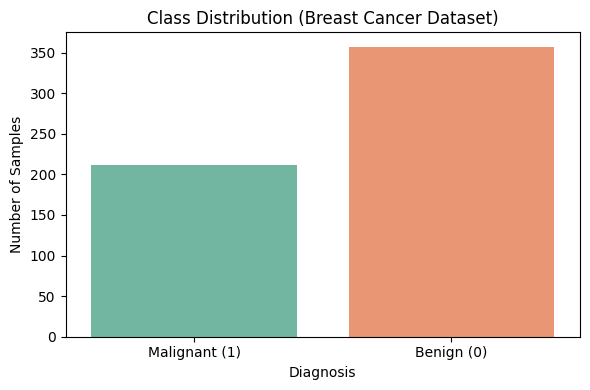

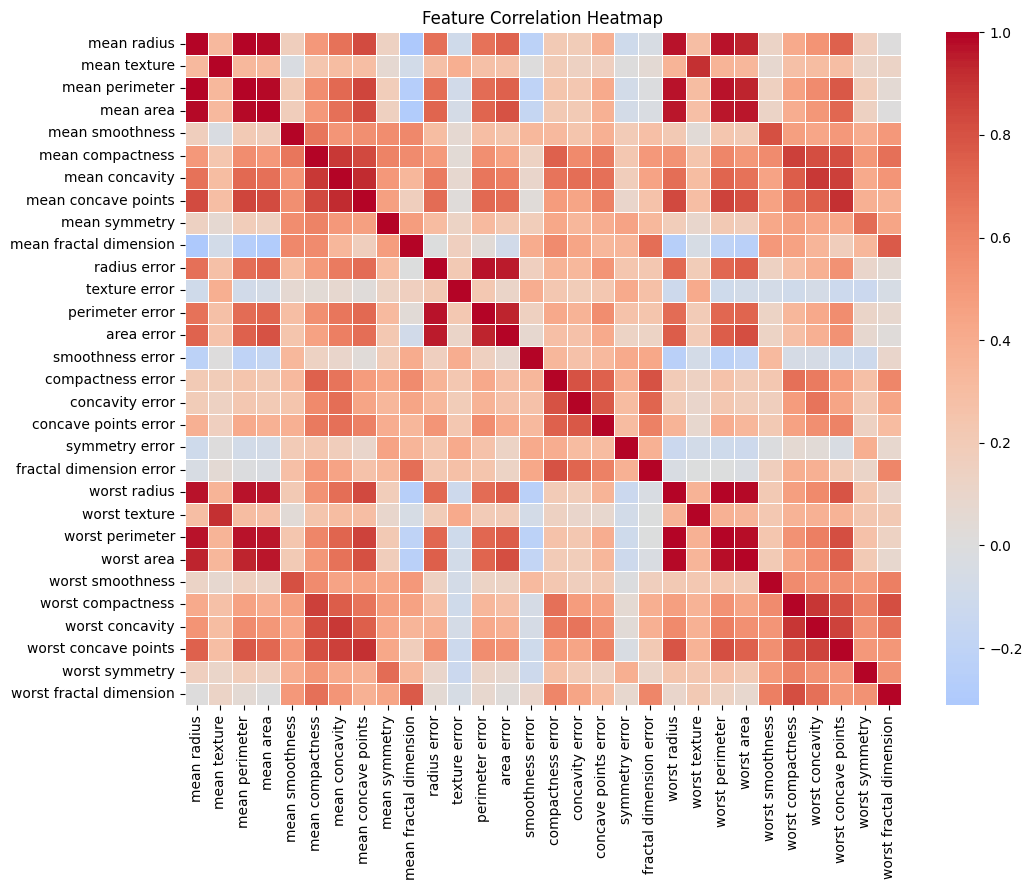

Highly correlated features to drop (|r| > 0.95) [7]:
['mean perimeter', 'mean area', 'perimeter error', 'area error', 'worst radius', 'worst perimeter', 'worst area']


In [3]:
# Summary statistics table (first 10 features)
display(X.describe().T[['mean', 'std', 'min', '50%', 'max']].head(10).round(3))

# Plot 1: Class Distribution
plt.figure(figsize=(6, 4))
sns.countplot(x=y.map({0: 'Benign (0)', 1: 'Malignant (1)'}), hue=y.map({0: 'Benign (0)', 1: 'Malignant (1)'}), palette='Set2', legend=False)
plt.title("Class Distribution (Breast Cancer Dataset)")
plt.ylabel("Number of Samples")
plt.xlabel("Diagnosis")
plt.tight_layout()
plt.savefig("figures/a1_class_dist.png", dpi=300)
plt.show()

# Plot 2: Correlation Heatmap
plt.figure(figsize=(11, 9))
corr_matrix = X.corr()
sns.heatmap(corr_matrix, cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.savefig("figures/a1_corr_heatmap.png", dpi=300)
plt.show()

# Identify highly correlated features (|r| > 0.95)
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
high_corr = [col for col in upper_tri.columns if any(upper_tri[col].abs() > 0.95)]
print(f"Highly correlated features to drop (|r| > 0.95) [{len(high_corr)}]:")
print(high_corr)


SPLIT AND MODEL TUNING


In [4]:
# Stratified 80/20 train-test split (prevents leakage)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)
print(f"Train samples: {X_train.shape[0]} | Test samples: {X_test.shape[0]}")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# Model 1: Logistic Regression (Baseline)
pipe_lr = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(random_state=SEED, max_iter=1000))
])
grid_lr = GridSearchCV(pipe_lr, {'clf__C': [0.01, 0.1, 1, 10]}, cv=cv, scoring='f1')
grid_lr.fit(X_train, y_train)

# Model 2: SVM (RBF Kernel)
pipe_svm = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', SVC(kernel='rbf', probability=True, random_state=SEED))
])
grid_svm = GridSearchCV(
    pipe_svm,
    {'clf__C': [0.1, 1, 10], 'clf__gamma': ['scale', 0.01, 0.001]},
    cv=cv, scoring='f1'
)
grid_svm.fit(X_train, y_train)

# Model 3: Random Forest
pipe_rf = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', RandomForestClassifier(random_state=SEED))
])
grid_rf = GridSearchCV(
    pipe_rf,
    {'clf__n_estimators': [100, 200], 'clf__max_depth': [None, 5, 10]},
    cv=cv, scoring='f1'
)
grid_rf.fit(X_train, y_train)

models = {
    "Logistic Regression": grid_lr,
    "SVM (RBF)": grid_svm,
    "Random Forest": grid_rf
}

print("\n--- 5-Fold Cross-Validation Results (Train Set) ---")
for name, grid in models.items():
    idx = grid.best_index_
    mean_f1 = grid.cv_results_['mean_test_score'][idx]
    std_f1 = grid.cv_results_['std_test_score'][idx]
    print(f"{name:20s} | Best Params: {grid.best_params_} | CV F1: {mean_f1:.4f} ± {std_f1:.4f}")

Train samples: 455 | Test samples: 114

--- 5-Fold Cross-Validation Results (Train Set) ---
Logistic Regression  | Best Params: {'clf__C': 1} | CV F1: 0.9640 ± 0.0207
SVM (RBF)            | Best Params: {'clf__C': 10, 'clf__gamma': 'scale'} | CV F1: 0.9674 ± 0.0114
Random Forest        | Best Params: {'clf__max_depth': 5, 'clf__n_estimators': 100} | CV F1: 0.9553 ± 0.0284


Test Set Evaluation & Result Plot

--- Final Test Set Evaluation ---


,Model,Accuracy,Precision,Recall,F1 (Malignant),ROC-AUC
0,Logistic Regression,0.9649,0.975,0.9286,0.9512,0.9960
1,SVM (RBF),0.9737,1.000,0.9286,0.9630,0.9927
2,Random Forest,0.9737,1.000,0.9286,0.9630,0.9950


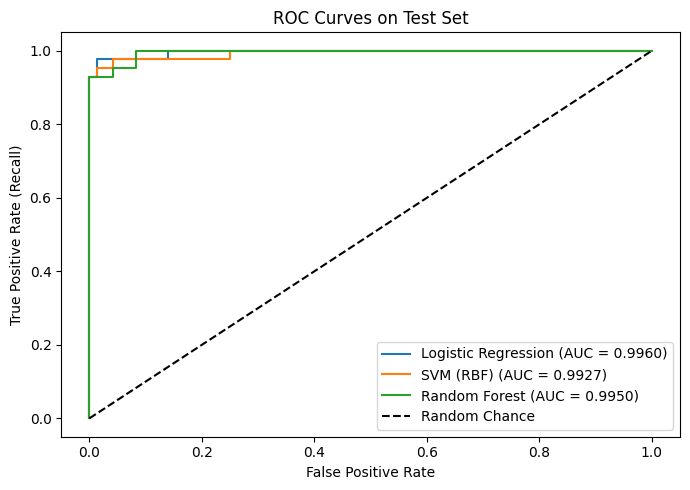

Best overall model selected: Random Forest


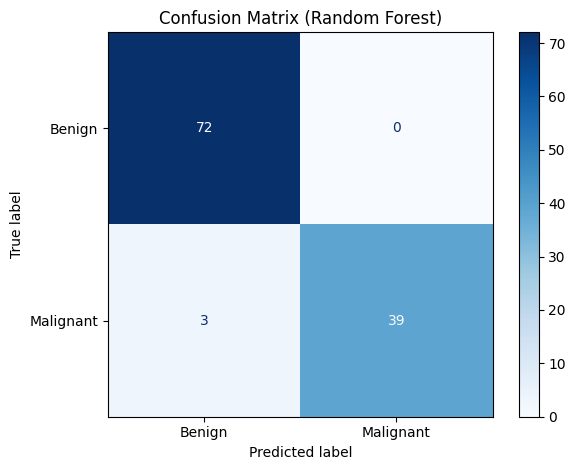

In [5]:
results = []
plt.figure(figsize=(7, 5))

for name, grid in models.items():
    best_model = grid.best_estimator_
    y_pred = best_model.predict(X_test)
    y_prob = best_model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 (Malignant)": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

    fpr, tpr, _ = roc_curve(y_test, y_prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, y_prob):.4f})")

results_df = pd.DataFrame(results)
print("--- Final Test Set Evaluation ---")
display(results_df.round(4))

# Save ROC Curve
plt.plot([0, 1], [0, 1], 'k--', label="Random Chance")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curves on Test Set")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("figures/a1_roc_curves.png", dpi=300)
plt.show()

# Pick best model (based on highest F1 / ROC-AUC)
best_name = results_df.sort_values(by=["F1 (Malignant)", "ROC-AUC"], ascending=False).iloc[0]["Model"]
best_overall = models[best_name].best_estimator_
print(f"Best overall model selected: {best_name}")

# Save Confusion Matrix for Best Model
disp = ConfusionMatrixDisplay.from_estimator(
    best_overall, X_test, y_test, display_labels=["Benign", "Malignant"], cmap="Blues"
)
plt.title(f"Confusion Matrix ({best_name})")
plt.tight_layout()
plt.savefig("figures/a1_confusion_matrix.png", dpi=300)
plt.show()

Threshold Study & Correlated Feature Experiment

In [6]:
# 1. Default threshold (0.50) metrics for best model
y_probs = best_overall.predict_proba(X_test)[:, 1]
y_pred_default = (y_probs >= 0.50).astype(int)
print(f"Default (0.50) -> Recall: {recall_score(y_test, y_pred_default):.4f}, Precision: {precision_score(y_test, y_pred_default):.4f}")
print("Default Confusion Matrix:\n", confusion_matrix(y_test, y_pred_default))

# 2. Threshold Study: Lower threshold until Malignant Recall >= 0.95
for t in np.arange(0.49, 0.05, -0.01):
    y_pred_t = (y_probs >= t).astype(int)
    rec = recall_score(y_test, y_pred_t)
    prec = precision_score(y_test, y_pred_t)
    if rec >= 0.95:
        print(f"\nAdjusted Threshold ({t:.2f}) -> Recall: {rec:.4f}, Precision: {prec:.4f}")
        print(f"Precision Drop: {precision_score(y_test, y_pred_default) - prec:.4f}")
        print("Adjusted Confusion Matrix:\n", confusion_matrix(y_test, y_pred_t))
        break

# 3. Top 5 Most Important Features (Logistic Regression coefficients)
coefs = pd.Series(grid_lr.best_estimator_.named_steps['clf'].coef_[0], index=X.columns)
print("\nTop 5 Most Influential Features (Logistic Regression |coef|):")
for feat, val in coefs.abs().sort_values(ascending=False).head(5).items():
    print(f"  {feat}: {coefs[feat]:.4f}")

# 4. Feature Redundancy Test: Drop highly correlated features (|r| > 0.95)
X_train_red = X_train.drop(columns=high_corr)
X_test_red = X_test.drop(columns=high_corr)

from sklearn.base import clone
model_red = clone(best_overall)
model_red.fit(X_train_red, y_train)
y_pred_red = model_red.predict(X_test_red)
y_prob_red = model_red.predict_proba(X_test_red)[:, 1]

print(f"\nAfter dropping {len(high_corr)} correlated features:")
print(f"  Accuracy: {accuracy_score(y_test, y_pred_red):.4f} | F1: {f1_score(y_test, y_pred_red):.4f} | ROC-AUC: {roc_auc_score(y_test, y_prob_red):.4f}")

Default (0.50) -> Recall: 0.9286, Precision: 1.0000
Default Confusion Matrix:
 [[72  0]
 [ 3 39]]

Adjusted Threshold (0.26) -> Recall: 0.9524, Precision: 0.9302
Precision Drop: 0.0698
Adjusted Confusion Matrix:
 [[69  3]
 [ 2 40]]

Top 5 Most Influential Features (Logistic Regression |coef|):
  worst texture: 1.4341
  radius error: 1.2333
  worst symmetry: 1.0613
  mean concave points: 0.9528
  worst concavity: 0.9114

After dropping 7 correlated features:
  Accuracy: 0.9474 | F1: 0.9250 | ROC-AUC: 0.9921
